In [24]:
import os
import sys
import warnings

sys.path.append("/path/to/GeneSPOT")
warnings.filterwarnings("ignore")

In [2]:
from pathlib import Path
from adjustText import adjust_text

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, zoomed_inset_axes
import mudata as mu
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.spatial import ConvexHull
import seaborn as sns
from statannotations.Annotator import Annotator
import matplotlib
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

matplotlib.rcParams['font.family'] = 'Aptos'
matplotlib.rcParams['pdf.fonttype'] = 42

In [3]:
from palettable.cartocolors.diverging import TealRose_7
from palettable.lightbartlein.diverging import BlueOrange8_8
from palettable.lightbartlein.sequential import Blues7_6
from palettable.cartocolors.diverging import Tropic_7
from palettable.cartocolors.sequential import PurpOr_7, agSunset_7

In [6]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything
from genespot.preprocess import preprocess_adata, filter_features, concat_features
from genespot.genespot import build_graph, topk_similar
from genespot.optimal_transports import cal_ot_distance
from genespot.graph_representation import node2vec
from genespot.visualization import create_cmap, legend_handles

random_state = 42
seed_everything(random_state)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
DATA_DIR = Path('/path/to/GeneSPOT/data/SMA')
RES_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/res/paired')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/fig3/outputs/paired')

os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

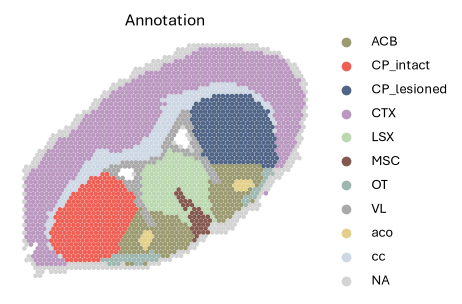

In [10]:
a1_mdata = mu.read_h5mu(RES_DIR / 'a1_mdata.h5mu')

annotations =        ['ACB',     'CP_intact', 'CP_lesioned', 'CTX',     'LSX',     'MSC',     'OT',      'VL',      'aco',     'cc']
annotations_colors = [
    '#9b9a71',  # ACB
    '#ee6055',  # CP_intact
    '#516587',  # CP_lesioned 
    '#ba98c0',  # CTX
    '#bbd8b0',  # LSX 
    '#84584e',  # MSC
    '#9eb8b1',  # OT
    '#a9a9a9',  # VL
    '#e2d08a',  # aco
    '#cdd8e4',  # cc
]
a1_mdata.uns['Annotation_colors'] = annotations_colors
annotations_legends = legend_handles(annotations, annotations_colors)
annotation_color_map = dict(
    zip(annotations, annotations_colors)
)

fig, axs = plt.subplots(1, 1, figsize=(4, 4))
sc.pl.embedding(
    a1_mdata, 
    color='Annotation', basis='spatial',
    title='Annotation',
    show=False, ax=axs,
    legend_loc='right margin',
    frameon=False)
axs.set_aspect(1)

cp_intact_coords = a1_mdata[a1_mdata.obs['Annotation'] == 'CP_intact'].obsm['spatial']
cp_intact_hull = ConvexHull(cp_intact_coords)
cp_intact_hull_points = cp_intact_coords[cp_intact_hull.vertices]
cp_intact_hull_points = np.vstack([cp_intact_hull_points, cp_intact_hull_points[0]])  # 闭合多边形


cp_lesioned_coords = a1_mdata[a1_mdata.obs['Annotation'] == 'CP_lesioned'].obsm['spatial']
cp_lesioned_hull = ConvexHull(cp_lesioned_coords)
cp_lesioned_hull_points = cp_lesioned_coords[cp_lesioned_hull.vertices]
cp_lesioned_hull_points = np.vstack([cp_lesioned_hull_points, cp_lesioned_hull_points[0]])  # 闭合多边形

plt.savefig(OUTPUTS_DIR / 'fig3a.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

#Genes: 835, #MBs: 182


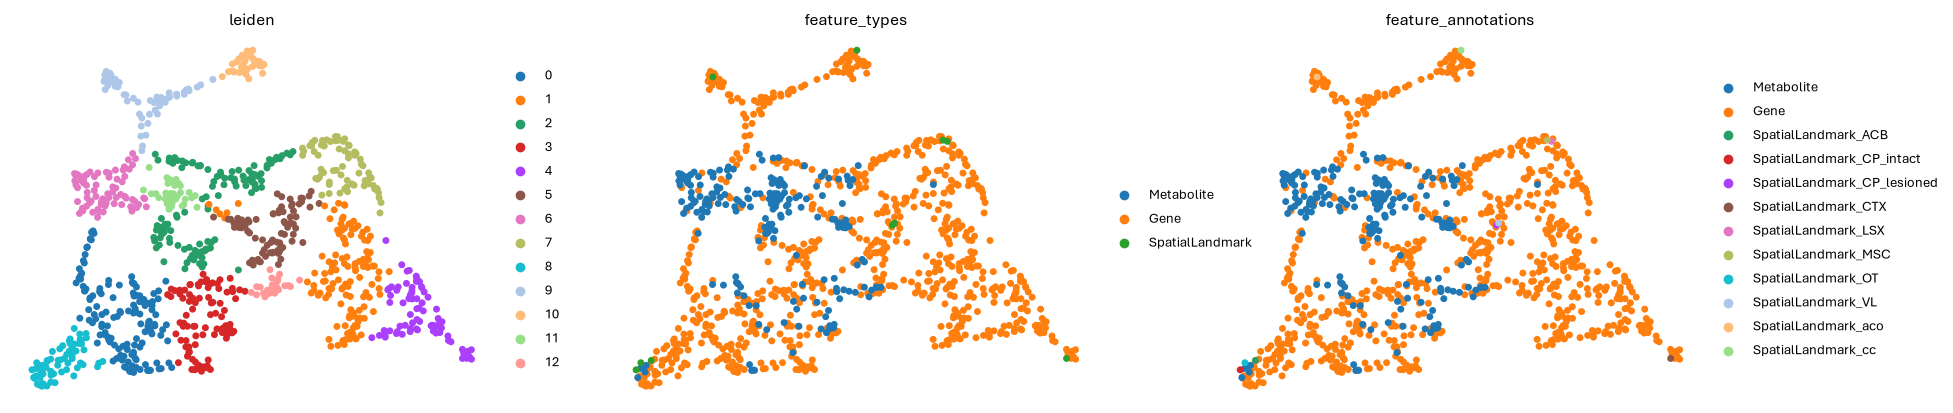

In [12]:
mdata = mu.read_h5mu(RES_DIR / 'a1_mdata.h5mu')
filtered_mdata = mdata[mdata.obs['Annotation'].notna()]
rna_adata = filtered_mdata['rna'].copy()
mb_adata = filtered_mdata['msi'].copy()
sc.pp.normalize_total(rna_adata, target_sum=1e4)
sc.pp.normalize_total(mb_adata, target_sum=1e4)
hvg_genes = filter_features(rna_adata, layer='raw', n_variable_genes=2000, expr_percent_filter=True, min_expr_percent=0.1, max_expr_percent=1)
hvg_mbs = filter_features(mb_adata, layer='raw', n_variable_genes=200, expr_percent_filter=True, min_expr_percent=0.1, max_expr_percent=1)
hvg_features = hvg_genes.tolist() + hvg_mbs.tolist()
print(f'#Genes: {len(hvg_genes)}, #MBs: {len(hvg_mbs)}')

paired_adata = concat_features(
    [rna_adata, mb_adata],
    feature_groups=['Gene', 'Metabolite']
)
paired_adata.obsm['SpatialGlue'] = filtered_mdata.obsm['SpatialGlue']
paired_adata.var['feature_names'] = paired_adata.var_names

gdata = sc.read_h5ad(RES_DIR / 'gdata.h5ad')
sc.pl.umap(gdata, color=['leiden', 'feature_types', 'feature_annotations'], edges=False, frameon=False, alpha=1, size=100)

In [13]:
gdata.obs[['UMAP_x', 'UMAP_y']] = gdata.obsm['X_umap']

feature_landmark_distance = []
feature_landmark = []
for feature in gdata.obs['feature_names']:
    landmark, distance, _ = topk_similar(
        query=feature, 
        gdata=gdata, 
        n=1,
        ftype='SpatialLandmark', 
        ftype_key='feature_types',
        query_mode='embedding',
        embedding_key='feature_embedding',
        smaller_is_better=False,
        metric='cosine_similarity',
    ).reset_index().values[0]
    feature_landmark_distance.append(distance)
    feature_landmark.append(landmark.split('_')[1])
    
gdata.obs['landmark_distance'] = feature_landmark_distance
gdata.obs['landmark'] = feature_landmark

In [14]:
marker_map = {
    'Gene': 'o',
    'Metabolite': '^',
    'SpatialLandmark': 'D',
    **dict(zip(annotations, ['D'] * len(annotations)))
}
color_map = {
    'Gene': '#005596',
    'Metabolite': '#ca6e28',
    'SpatialLandmark': 'grey',
    **annotation_color_map
}

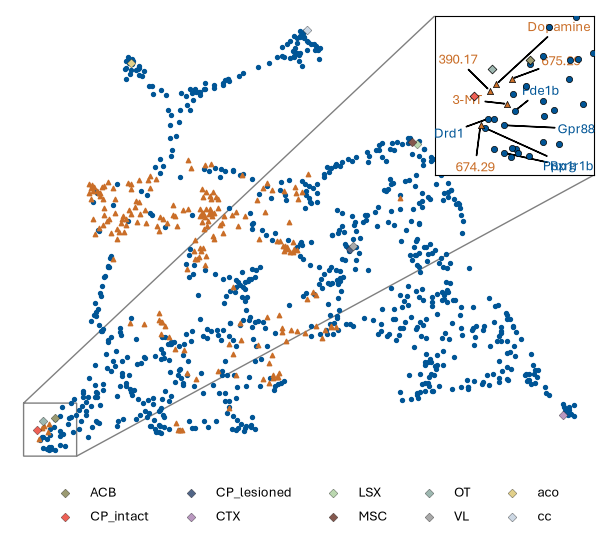

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

axins = zoomed_inset_axes(ax, zoom=3, loc="upper right")
axins.set_title('')
x_loc, y_loc = gdata['SpatialLandmark_CP_intact'].obs[['UMAP_x', 'UMAP_y']].values[0]
axins.set_xlim(x_loc-0.5, x_loc+1.5)
axins.set_ylim(y_loc-1, y_loc+1)
# axins.invert_xaxis()
axins.set_xticks([])
axins.set_yticks([])
axins.set_xlabel('')
axins.set_ylabel('')
ax.indicate_inset_zoom(axins, edgecolor="black")


ploted_leidens = []
for ann in annotations:
    landmark = gdata[f'SpatialLandmark_{ann}']
    landmark_leiden = landmark.obs['leiden'].item()
    ax.scatter(
        x=landmark.obs['UMAP_x'], y=landmark.obs['UMAP_y'],
        c=color_map[ann],
        marker=marker_map[ann],
        s=20, edgecolors='black', linewidths=0.2,
        label=ann, 
        zorder=999,
    )

    axins.scatter(
        x=landmark.obs['UMAP_x'], y=landmark.obs['UMAP_y'],
        c=color_map[ann],
        marker=marker_map[ann],
        s=20, edgecolors='black', linewidths=0.2,
        label=ann, 
        zorder=999,
    )
    
for feature_type in ['Gene', 'Metabolite']:
    points = gdata[gdata.obs['feature_types'] == feature_type]
    ax.scatter(
        points.obs['UMAP_x'], points.obs['UMAP_y'],
        c=color_map[feature_type],
        marker=marker_map[feature_type],
        s=8 if feature_type == 'Gene' else 10, edgecolors=None,
        zorder=100 if feature_type == 'Gene' else 101
    )

    axins.scatter(
        points.obs['UMAP_x'], points.obs['UMAP_y'],
        c=color_map[feature_type],
        marker=marker_map[feature_type],
        s=20, edgecolors=None,
        zorder=100 if feature_type == 'Gene' else 101
    )


for collection in axins.collections:
    collection.set_edgecolor('black')
    collection.set_linewidth(0.5)

texts = []
cp_intact_top5_metas = topk_similar(
    f'SpatialLandmark_CP_intact', 
    gdata, 
    n=5,
    ftype='Metabolite', 
    ftype_key='feature_types',
    query_mode='embedding',
    embedding_key='feature_embedding',
    smaller_is_better=False, metric='cosine_similarity',
).index.values.tolist()

for meta in cp_intact_top5_metas:
    x_loc, y_loc = gdata[meta].obs[['UMAP_x', 'UMAP_y']].values[0]
    color_point = color_map['Metabolite']
    texts.append(axins.text(x_loc, y_loc, meta, color=color_point, fontsize=10, clip_on=False))

cp_intact_top5_genes = topk_similar(
    f'SpatialLandmark_CP_intact',
    gdata, 
    n=5,
    ftype='Gene', 
    ftype_key='feature_types',
    query_mode='embedding',
    embedding_key='feature_embedding',
    smaller_is_better=False, metric='cosine_similarity',
).index.values.tolist()

for meta in cp_intact_top5_genes:
    x_loc, y_loc = gdata[meta].obs[['UMAP_x', 'UMAP_y']].values[0]
    color_point = color_map['Gene']
    texts.append(axins.text(x_loc, y_loc, meta, color=color_point, fontsize=10, clip_on=False))

_ = adjust_text(
    texts,
    expand=(2, 2),
    arrowprops=dict(color="black", lw=1),
    ax=axins,
)

ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_xticks([], [])
ax.set_yticks([], [])
ax.set_title('')
ax.set_aspect(1)

# **调整图例**
legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 0.),
    ncol=5,
    frameon=False
)
plt.savefig(OUTPUTS_DIR / 'fig3c.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

Dopamine: Intact = 91457.733 +/- 3368.082 (n=314), Lesioned = 6896.669 +/- 1118.029 (n=296)
  p = 4.19e-86
3-MT: Intact = 156453.204 +/- 3893.664 (n=314), Lesioned = 6219.552 +/- 1160.125 (n=296)
  p = 3.61e-153
674.29: Intact = 145389.685 +/- 3640.258 (n=314), Lesioned = 6308.954 +/- 972.346 (n=296)
  p = 1.06e-152
675.29: Intact = 66016.625 +/- 2595.267 (n=314), Lesioned = 13037.713 +/- 1723.869 (n=296)
  p = 2.65e-52
390.17: Intact = 343271.333 +/- 7623.461 (n=314), Lesioned = 14532.306 +/- 1916.599 (n=296)
  p = 6.23e-176


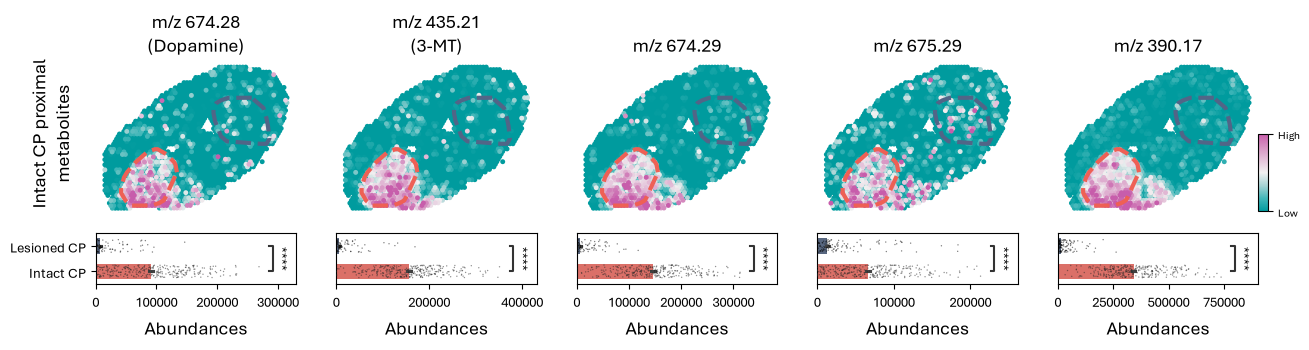

In [35]:
metas_profile = topk_similar(
    f'SpatialLandmark_CP_intact', 
    gdata,
    n=5,
    ftype='Metabolite', 
    ftype_key='feature_types',
    query_mode='embedding',
    embedding_key='feature_embedding',
    smaller_is_better=False, metric='cosine_similarity',
).index.values.tolist()
fig, axs = plt.subplots(
    2, 5,
    figsize=(15, 3),
    gridspec_kw={'height_ratios': [1, 0.3]},
)
intact_adata = paired_adata[paired_adata.obs['Annotation'] == 'CP_intact']
lesioned_adata = paired_adata[paired_adata.obs['Annotation'] == 'CP_lesioned']

for i, meta in enumerate(metas_profile):
    
    ax = axs[0, i]
    if meta == 'Dopamine':
        title = 'm/z 674.28\n(Dopamine)'
    elif meta == '3-MT':
        title = 'm/z 435.21\n(3-MT)'
    else:
        title = f'm/z {meta}'
        
    sc.pl.embedding(paired_adata, color=meta, basis='spatial', layer='raw', ax=ax, show=False, frameon=False, cmap=Tropic_7.mpl_colormap, colorbar_loc=None, vmax='p99')
    ax.set_title(title, fontsize=14)
    ax.set_aspect(1)
    
    ax.plot(cp_intact_hull_points[:, 0], cp_intact_hull_points[:, 1], color=annotation_color_map['CP_intact'], linewidth=3, linestyle='--', dash_capstyle='butt')
    ax.plot(cp_lesioned_hull_points[:, 0], cp_lesioned_hull_points[:, 1], color=annotation_color_map['CP_lesioned'], linewidth=3, linestyle='--', dash_capstyle='butt')

    intact_cnt = intact_adata[:, meta].layers['raw'].reshape(-1, )
    lesioned_cnt = lesioned_adata[:, meta].layers['raw'].reshape(-1, )
    
    plt_data = pd.DataFrame(np.concatenate([intact_cnt, lesioned_cnt]))
    plt_data.columns = ['CNT']
    plt_data['Group'] = ['Intact'] * len(intact_cnt) + ['Lesioned'] * len(lesioned_cnt)

    ax_bar = axs[1, i]
    sns.barplot(
        data=plt_data, x='CNT', y='Group',
        hue='Group', hue_order=['Intact', 'Lesioned'],
        orient='h',
        width=0.6,
        ax=ax_bar,
        errorbar='se',
        palette=[annotation_color_map['CP_intact'], annotation_color_map['CP_lesioned']],
        legend=False
    )
    sns.stripplot(
        data=plt_data, x='CNT', y='Group',
        hue='Group', hue_order=['Intact', 'Lesioned'],
        orient='h',
        ax=ax_bar,
        dodge=False,
        jitter=0.25,
        size=1,
        alpha=0.5,
        edgecolor='none',
        linewidth=0.2,
        color='black',
        legend=False
    )

    box_pairs = [("Intact", "Lesioned")]
    annotator = Annotator(ax_bar, box_pairs, data=plt_data, x='CNT', y='Group', orient='h')
    annotator.configure(test='t-test_ind', text_format='star', loc='inside', verbose=0)
    annotator.apply_and_annotate()

    intact_mean, intact_sem = intact_cnt.mean(), intact_cnt.std(ddof=1) / np.sqrt(len(intact_cnt))
    lesioned_mean, lesioned_sem = lesioned_cnt.mean(), lesioned_cnt.std(ddof=1) / np.sqrt(len(lesioned_cnt))
    print(f"{meta}: Intact = {intact_mean:.3f} +/- {intact_sem:.3f} (n={len(intact_cnt)}), "
          f"Lesioned = {lesioned_mean:.3f} +/- {lesioned_sem:.3f} (n={len(lesioned_cnt)})")
    for ann in annotator.annotations:
        print(f"  p = {ann.data.pvalue:.2e}")
    
    ax_bar.set_ylim(-0.5, 1.5)
    if i == 0:
        ax_bar.set_yticks([0, 1])
        ax_bar.set_yticklabels(['Intact CP', 'Lesioned CP'])
    else:
        ax_bar.set_yticks([])
        ax_bar.set_yticklabels([])
    ax_bar.set_ylabel('')
    ax_bar.set_xlabel('Abundances', fontsize=14)

last_ax = axs[0,-1]
last_ax_pos = last_ax.get_position()
fig_width, fig_height = fig.get_figwidth(), fig.get_figheight()
cbar_width = 0.1 / fig_width
cbar_gap = 0
cbar_height = last_ax_pos.height * 0.5
cbar_x = last_ax_pos.x1 + cbar_gap
cbar_y = last_ax_pos.y0
cax = fig.add_axes([cbar_x, cbar_y, cbar_width, cbar_height])

norm = plt.Normalize(vmin=0, vmax=1)
cmap = Tropic_7.mpl_colormap
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, cax=cax, orientation='vertical')
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['Low', 'High'])

fontsize = max(8, min(12, fig_height * 0.6))
cbar.ax.tick_params(labelsize=fontsize)
ax.set_aspect(1)

first_ax_pos = axs[0, 0].get_position()
text_x = first_ax_pos.x0 - 0.03
text_y = first_ax_pos.y0 + first_ax_pos.height / 2

fig.text(
    text_x, text_y,
    'Intact CP proximal\nmetabolites', 
    ha='center', va='center', 
    fontsize=14, rotation=90
)

plt.subplots_adjust(hspace=0.1)
plt.savefig(OUTPUTS_DIR / 'fig3d1.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

Ppp1r1b: Intact = 6.236 +/- 0.261 (n=314), Lesioned = 5.139 +/- 0.191 (n=296)
  p = 8.38e-04
Gpr88: Intact = 5.290 +/- 0.227 (n=314), Lesioned = 3.912 +/- 0.155 (n=296)
  p = 9.12e-07
Pde1b: Intact = 6.475 +/- 0.267 (n=314), Lesioned = 5.047 +/- 0.198 (n=296)
  p = 2.41e-05
Drd1: Intact = 1.299 +/- 0.080 (n=314), Lesioned = 0.868 +/- 0.060 (n=296)
  p = 2.30e-05
Rxrg: Intact = 0.997 +/- 0.061 (n=314), Lesioned = 0.784 +/- 0.057 (n=296)
  p = 1.11e-02


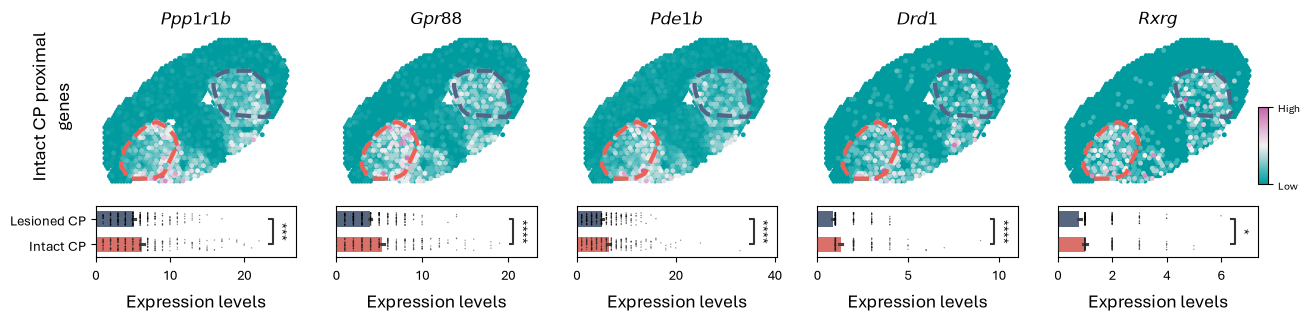

In [34]:
genes_profile = topk_similar(
    f'SpatialLandmark_CP_intact', 
    gdata,
    n=5,
    ftype='Gene', 
    ftype_key='feature_types',
    query_mode='embedding',
    embedding_key='feature_embedding',
    smaller_is_better=False, metric='cosine_similarity',
).index.values.tolist()

fig, axs = plt.subplots(
    2, 5,
    figsize=(15, 3),
    gridspec_kw={'height_ratios': [1, 0.3]},
)
intact_adata = paired_adata[paired_adata.obs['Annotation'] == 'CP_intact']
lesioned_adata = paired_adata[paired_adata.obs['Annotation'] == 'CP_lesioned']

for i, gene in enumerate(genes_profile):
    
    ax = axs[0, i]
    sc.pl.embedding(paired_adata, color=gene, layer='raw', basis='spatial', ax=ax, show=False, frameon=False, cmap=Tropic_7.mpl_colormap, colorbar_loc=None)
    ax.set_title(f'${gene}$', style='italic')
    ax.set_aspect(1)
    
    ax.plot(cp_intact_hull_points[:, 0], cp_intact_hull_points[:, 1], color=annotation_color_map['CP_intact'], linewidth=3, linestyle='--', dash_capstyle='butt')
    ax.plot(cp_lesioned_hull_points[:, 0], cp_lesioned_hull_points[:, 1], color=annotation_color_map['CP_lesioned'], linewidth=3, linestyle='--', dash_capstyle='butt')

    intact_cnt = intact_adata[:, gene].layers['raw'].reshape(-1, )
    lesioned_cnt = lesioned_adata[:, gene].layers['raw'].reshape(-1, )
    
    plt_data = pd.DataFrame(np.concatenate([intact_cnt, lesioned_cnt]))
    plt_data.columns = ['CNT']
    plt_data['Group'] = ['Intact'] * len(intact_cnt) + ['Lesioned'] * len(lesioned_cnt)

    ax_bar = axs[1, i]
    sns.barplot(
        data=plt_data, x='CNT', y='Group',
        hue='Group', hue_order=['Intact', 'Lesioned'],
        orient='h',
        width=0.6,
        ax=ax_bar,
        errorbar='se',
        palette=[annotation_color_map['CP_intact'], annotation_color_map['CP_lesioned']],
        legend=False
    )
    sns.stripplot(
        data=plt_data, x='CNT', y='Group',
        hue='Group', hue_order=['Intact', 'Lesioned'],
        orient='h',
        ax=ax_bar,
        dodge=False,
        jitter=0.25,
        size=1,
        alpha=0.5,
        edgecolor='none',
        linewidth=0.2,
        color='black',
        legend=False
    )


    box_pairs = [("Intact", "Lesioned")]
    annotator = Annotator(ax_bar, box_pairs, data=plt_data, x='CNT', y='Group', orient='h')
    annotator.configure(test='t-test_ind', text_format='star', loc='inside', verbose=0)
    annotator.apply_and_annotate()

    intact_mean, intact_sem = intact_cnt.mean(), intact_cnt.std(ddof=1) / np.sqrt(len(intact_cnt))
    lesioned_mean, lesioned_sem = lesioned_cnt.mean(), lesioned_cnt.std(ddof=1) / np.sqrt(len(lesioned_cnt))
    print(f"{gene}: Intact = {intact_mean:.3f} +/- {intact_sem:.3f} (n={len(intact_cnt)}), "
          f"Lesioned = {lesioned_mean:.3f} +/- {lesioned_sem:.3f} (n={len(lesioned_cnt)})")
    for ann in annotator.annotations:
        print(f"  p = {ann.data.pvalue:.2e}")
    
    ax_bar.set_ylim(-0.5, 1.5)
    if i == 0:
        ax_bar.set_yticks([0, 1], ['Intact CP', 'Lesioned CP'])
    else:
        ax_bar.set_yticks([], [])
    ax_bar.set_ylabel('')
    ax_bar.set_xlabel('Expression levels', fontsize=14)


last_ax = axs[0,-1]
last_ax_pos = last_ax.get_position()
fig_width, fig_height = fig.get_figwidth(), fig.get_figheight()
cbar_width = 0.1 / fig_width
cbar_gap = 0
cbar_height = last_ax_pos.height * 0.5
cbar_x = last_ax_pos.x1 + cbar_gap
cbar_y = last_ax_pos.y0
cax = fig.add_axes([cbar_x, cbar_y, cbar_width, cbar_height])

norm = plt.Normalize(vmin=0, vmax=1)
cmap = Tropic_7.mpl_colormap
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, cax=cax, orientation='vertical')
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['Low', 'High'])

fontsize = max(8, min(12, fig_height * 0.6))
cbar.ax.tick_params(labelsize=fontsize)
ax.set_aspect(1)

first_ax_pos = axs[0, 0].get_position()
text_x = first_ax_pos.x0 - 0.03
text_y = first_ax_pos.y0 + first_ax_pos.height / 2

fig.text(
    text_x, text_y,
    'Intact CP proximal\ngenes', 
    ha='center', va='center', 
    fontsize=14, rotation=90
)

plt.subplots_adjust(hspace=0.1)
plt.savefig(OUTPUTS_DIR / 'fig3d2.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()